## DATS 6103 Final Report
**Arpita Gonnade, Mia Alecia Goins, Simon Tao**

**Introduction and Data Description**

...

In [30]:
# Libraries installation - one time run required
pip install pandas
pip install numpy 
pip install matplotlib 
pip install seaborn 
pip install scikit-learn

SyntaxError: invalid syntax (1666230871.py, line 2)

In [37]:
pip install matplotlib 

  Using cached matplotlib-3.9.4-cp39-cp39-macosx_11_0_arm64.whl (7.8 MB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
  Using cached kiwisolver-1.4.7-cp39-cp39-macosx_11_0_arm64.whl (64 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached fonttools-4.60.2-cp39-cp39-macosx_10_9_universal2.whl (2.9 MB)
  Using cached contourpy-1.3.0-cp39-cp39-macosx_11_0_arm64.whl (249 kB)
  Using cached pillow-11.3.0-cp39-cp39-macosx_11_0_arm64.whl (4.7 MB)
You should consider upgrading via the '/Users/arpitagonnade/Arpita_study_materials/Data Mining/Python_practise/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [41]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
You should consider upgrading via the '/Users/arpitagonnade/Arpita_study_materials/Data Mining/Python_practise/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached scikit_learn-1.6.1-cp39-cp39-macosx_12_0_arm64.whl (11.1 MB)
  Using cached scipy-1.13.1-cp39-cp39-macosx_12_0_arm64.whl (30.3 MB)
  Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


Dataset link : https://www.kaggle.com/datasets/flynn28/nhl-player-database/data 

In [73]:
# Libraries
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    PrecisionRecallDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
skaters = pd.read_csv("Dataset/SKATERS.csv")
goalies = pd.read_csv("Dataset/GOALIES.csv")

In [76]:
skaters.head()

,name,first,last,position,games,goals,assists,time,active,hof
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,False
1,Wyatt Aamodt,2025,2025,D,2,1,0,34.0,True,False
2,Reg Abbott,1953,1953,C,3,0,0,NaN,False,False
3,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,False
4,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,False


In [77]:
goalies.head()

,name,first,last,games,started,wins,losses,conceded,saves,minutes,goals,assists,active,hof
0,George Abbott,1944,1944,1,NaN,0.0,1.0,7,NaN,60,0,0,False,False
1,John Adams,1973,1975,22,NaN,9.0,10.0,85,605.0,1180,0,0,False,False
2,David Aebischer,2001,2008,214,1.0,106.0,74.0,513,5294.0,12230,0,5,False,False
3,John Aiken,1958,1958,1,NaN,0.0,1.0,6,12.0,34,0,0,False,False
4,Andy Aitkenhead,1933,1935,106,NaN,47.0,43.0,257,NaN,6570,0,0,False,False


In [78]:
#checking columns
skaters.columns.tolist()

['name',
 'first',
 'last',
 'position',
 'games',
 'goals',
 'assists',
 'time',
 'active',
 'hof']

In [79]:
# checking datatypes for all columns
skaters.dtypes

name         object
first         int64
last          int64
position     object
games         int64
goals         int64
assists       int64
time        float64
active         bool
hof            bool
dtype: object

# EDA
1) eligible skaters using skaters dataset
2) whether any players have missing or unusual career-end dates.

The Hockey Hall of Fame has an eligibility waiting period of three years after a player's last professional game. Thus, we are considering skaters who played last game before or till 2022 as eligible for HOF.

# BEGIN SKATERS INVESTIGATION

In [138]:
# Number of players who are still active
eligible_skaters = skaters[skaters['last'].notna() & (skaters['last'] <= 2022)]
eligible_skaters.shape


(6575, 10)

In [131]:
# re-checking if any eligible skaters is still active
len(eligible_skaters[eligible_skaters["active"]==True])

0

In [132]:
len(eligible_skaters)

6575

Interpretation:
There are total 6575 players from 7785 who are eligible for hall of fame (3 years after the career end)

In [145]:
eligible_skaters.isnull().sum()

name           0
first          0
last           0
position       0
games          0
goals          0
assists        0
time        3566
active         0
hof            0
dtype: int64

Time on ice is missing for large players (around 3566). Diving deep into the missing time on ice values

In [134]:
eligible_skaters[eligible_skaters["time"].isnull() == True]

,name,first,last,position,games,goals,assists,time,active,hof
2,Reg Abbott,1953,1953,C,3,0,0,NaN,False,False
5,Clarence Abel,1927,1934,D,333,20,18,NaN,False,False
6,Gerry Abel,1967,1967,LW,1,0,0,NaN,False,False
7,Sid Abel,1939,1954,C/LW,612,188,284,NaN,False,True
9,Dennis Abgrall,1976,1976,RW,13,0,2,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...
7754,Lars Zetterström,1979,1979,D,14,0,1,NaN,False,False
7770,Marty Zoborosky,1945,1945,D,1,0,0,NaN,False,False
7773,Rick Zombo,1985,1996,D,652,24,130,NaN,False,False
7781,Mike Zuke,1979,1986,C,455,86,196,NaN,False,False


In [136]:
len(eligible_skaters[(eligible_skaters["first"]>= 1918) & (eligible_skaters["last"] <= 1998)])

3655

In [122]:

# Filter rows where time_on_ice is missing
missing_toi = eligible_skaters[eligible_skaters["time"].isna()]
missing_toi
# Find earliest and latest seasons
first_season = missing_toi["first"].min()
last_season = missing_toi["last"].max()

print("First season with missing TOI:", first_season)
print("Last season with missing TOI:", last_season)
len(missing_toi)

First season with missing TOI: 1918
Last season with missing TOI: 1998


3566

In [128]:
# Filter rows where time_on_ice is missing
not_missing_toi = eligible_skaters[eligible_skaters["time"].notna()]

print(len(not_missing_toi[(not_missing_toi["first"] >= 1918) & (not_missing_toi["last"] <= 1998)]))
print(len(not_missing_toi[(not_missing_toi["first"] >= 1918) & (not_missing_toi["last"] <= 1998) & (not_missing_toi["hof"] == 1)]))

89
10


Observation:
Total there are 3655 whose playing career is between 1918 to 1998.

3566 players  has missing time on ice played during 1918 to 1998. 

Only 89 players have their time recorded during the same years.

Among them only 10 players were awarded as hall of fame. 

In [89]:
eligible_skaters.describe()

,first,last,games,goals,assists,time
count,6575.000000,6575.000000,6575.000000,6575.000000,6575.000000,3009.000000
mean,1983.331103,1988.847452,272.050951,47.684259,77.331103,3975.345962
std,25.196859,25.599095,337.523920,90.931791,138.890740,5574.857366
min,1918.000000,1918.000000,0.000000,0.000000,0.000000,1.000000
25%,1971.000000,1977.000000,17.000000,1.000000,2.000000,159.000000
50%,1988.000000,1994.000000,106.000000,8.000000,15.000000,1208.000000
75%,2003.000000,2009.000000,450.000000,50.000000,92.000000,6028.000000
max,2022.000000,2022.000000,1779.000000,894.000000,1963.000000,39485.000000


In [90]:
# checking if there are duplicate complete row
eligible_skaters.duplicated().sum()

np.int64(0)

In [91]:
eligible_skaters["name"].duplicated().sum()

np.int64(53)

In [92]:
eligible_skaters[eligible_skaters["name"] == "Ron Anderson"]

,name,first,last,position,games,goals,assists,time,active,hof
107,Ron Anderson,1968,1972,RW,251,28,30,NaN,False,False
108,Ron Anderson,1975,1975,RW,28,9,7,NaN,False,False


In [93]:
# checking any names duplicates
eligible_skaters[eligible_skaters["name"].duplicated()]

,name,first,last,position,games,goals,assists,time,active,hof
26,Greg Adams,1985,2001,LW,1056,355,388,4059.0,False,False
108,Ron Anderson,1975,1975,RW,28,9,7,NaN,False,False
121,Peter Andersson,1993,1994,D,47,6,13,NaN,False,False
146,Syl Apps,1971,1980,C,727,183,423,NaN,False,False
246,Ace Bailey,1969,1978,LW,568,107,171,NaN,False,False
605,Mike Boland,1975,1979,D,23,1,2,NaN,False,False
838,Mike Brown,2008,2016,RW,407,19,17,3351.0,False,False
1264,Sean Collins,2013,2016,C,21,0,3,211.0,False,False
1351,Alain Côté,1986,1994,D,119,2,18,NaN,False,False
1592,Ab DeMarco,1970,1979,D,344,44,80,NaN,False,False


In [94]:
# taking 2 skater's at random to observe the rows
print(eligible_skaters[eligible_skaters["name"] == "Ron Anderson"])
print(eligible_skaters[eligible_skaters["name"] == "Greg Adams"])

             name  first  last position  games  goals  assists  time  active  \
107  Ron Anderson   1968  1972       RW    251     28       30   NaN   False   
108  Ron Anderson   1975  1975       RW     28      9        7   NaN   False   

       hof  
107  False  
108  False  
          name  first  last position  games  goals  assists    time  active  \
25  Greg Adams   1981  1990       LW    544     84      143     NaN   False   
26  Greg Adams   1985  2001       LW   1056    355      388  4059.0   False   

      hof  
25  False  
26  False  


There are duplicate names but the person are different (checked on internet), thus all the duplicate entries being kept in the dataset

In [167]:
eligible_skaters.columns

Index(['name', 'first', 'last', 'position', 'games', 'goals', 'assists',
       'time', 'active', 'hof'],
      dtype='object')

# END OF SKATERS INVESTIGATION

# BEGIN GOALIES INVESTIGATION

In [143]:
eligible_goalies = goalies[goalies["last"].notna() & (goalies["last"] <= 2022)]
eligible_goalies.shape

(729, 14)

In [146]:
eligible_goalies.isnull().sum()

name          0
first         0
last          0
games         0
started     525
wins          2
losses        2
conceded      0
saves        88
minutes       0
goals         0
assists       0
active        0
hof           0
dtype: int64

In [149]:
# Filter rows where time_on_ice is missing
missing_started = eligible_goalies[eligible_goalies["started"].isna()]
print(len(missing_started))
# Find earliest and latest seasons
first_season = missing_started["first"].min()
last_season = missing_started["last"].max()

print("First season with missing TOI:", first_season)
print("Last season with missing TOI:", last_season)
len(missing_started[(eligible_goalies["last"] <= 1998)])

525
First season with missing TOI: 1918
Last season with missing TOI: 2007


400

In [155]:
era_goalies = missing_started[(eligible_goalies["last"] > 1998) & (eligible_goalies["last"] <= 2007)]

#### Interpretation:
For goalies dataset 525 goalies have missing 'started' values.

Out of which 400 goalies carrer ended and before 1998, only 125 goalies career ended after 1998.

In [158]:
# to check players career having missing 'saves'

missing_saves = eligible_goalies[eligible_goalies["saves"].isna()]
print(len(missing_saves))
# Find earliest and latest seasons
first_season = missing_saves["first"].min()
last_season = missing_saves["last"].max()

print("First season with missing TOI:", first_season)
print("Last season with missing TOI:", last_season)


88
First season with missing TOI: 1918
Last season with missing TOI: 1955


#### Interpretation

All goalies having missing saves are from years 1918 to 1955.

In [168]:
eligible_goalies.columns

Index(['name', 'first', 'last', 'games', 'started', 'wins', 'losses',
       'conceded', 'saves', 'minutes', 'goals', 'assists', 'active', 'hof'],
      dtype='object')

# END OF GOALIES INVESTIGATION

## Question

1) Shall we drop (get rid) of duplicates ? no, they are different players
2) Shall we merge rows considering first as lowest among both year and last as highest among both year?
    if merged:
    a) how can we segregate years that gets overlapped?
    b) shall time be added? if so rows with NaN values justifies the exact time or this will be misleading?
    c) there is a possibility of change in position, does position columns represents both ?

### Report from initial EDA
1) Considering career-end year as 2022 and no missing last year ("last") of play, the skaters who are eligible for hall of fame as of now (2026) are 6575.
2) There are no eligible skaters who are active now (2026) (this is done to cross verify data and their status if it says still active)
3) for 3566 skaters, the time on ice is not missing (Nan).
4) There are total 53 duplicate rows.

#### Visual Representation of Original data
1) To check if the data is imbalance (target variables), we have build a bar graph

In [95]:
# visualization - eligibility distribution - create a pie chart to show eligibility distribution
# convert charaters to numericals
eligible_skaters["hof"] = eligible_skaters["hof"].astype(int)

eligible_skaters["hof"].head()
hof_counts = eligible_skaters.value_counts(eligible_skaters["hof"])
hof_counts

hof
0    6350
1     225
Name: count, dtype: int64

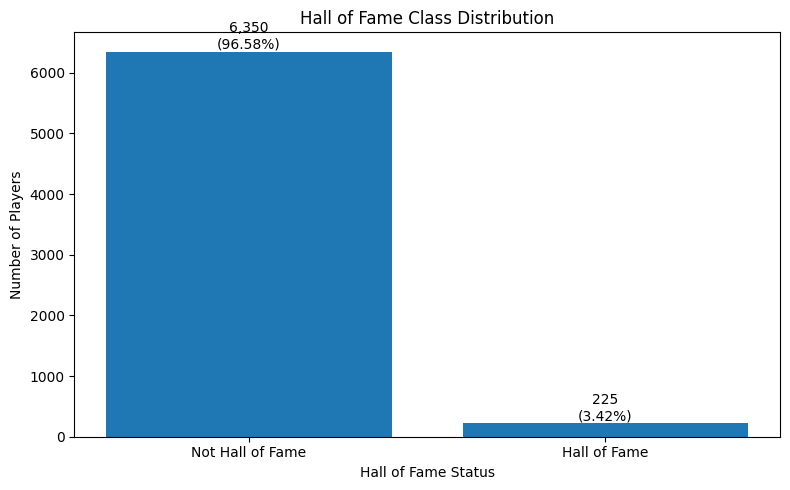

In [96]:
hof_percentages = hof_counts / hof_counts.sum() * 100

labels = ["Not Hall of Fame", "Hall of Fame"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    hof_counts.values
)

ax.set_title("Hall of Fame Class Distribution")
ax.set_xlabel("Hall of Fame Status")
ax.set_ylabel("Number of Players")

for bar, count, pct in zip(
    bars, hof_counts.values, hof_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Interpretation
From the observation, one bar that is much taller than the other, indicating class imbalance.
The target variable is imbalanced, with a substantially larger proportion of non-Hall of Fame players than Hall of Fame players.

#### Imbalance can also be reported using summary report

In [97]:
# Update these names to match df.columns
numeric_cols = [
    "goals",
    "assists",
    "games",
    "time"
]
# Keep only columns that actually exist and are numeric
numeric_cols = [
    col for col in numeric_cols
    if col in eligible_skaters.columns and pd.api.types.is_numeric_dtype(eligible_skaters[col])
]
summary = pd.DataFrame(index=numeric_cols)
df= eligible_skaters
summary["count"] = df[numeric_cols].count()
summary["mean"] = df[numeric_cols].mean()
summary["median"] = df[numeric_cols].median()
summary["std_sample"] = df[numeric_cols].std(ddof=1)
summary["variance_sample"] = df[numeric_cols].var(ddof=1)

summary["mean_minus_median"] = summary["mean"] - summary["median"]
summary["mean_median_ratio"] = (
    summary["mean"] / summary["median"].replace(0, np.nan)
)

summary.round(2)

,count,mean,median,std_sample,variance_sample,mean_minus_median,mean_median_ratio
goals,6575,47.68,8.0,90.93,8268.59,39.68,5.96
assists,6575,77.33,15.0,138.89,19290.64,62.33,5.16
games,6575,272.05,106.0,337.52,113922.40,166.05,2.57
time,3009,3975.35,1208.0,5574.86,31079034.65,2767.35,3.29


Interpretation:
- If the mean goals or assists is much higher than the median, a smaller group of high-scoring players may be pulling the mean upward.
- If the standard deviation is large relative to the mean, player career totals vary substantially.
- Compare career totals with per-game rates if available. Totals partly reflect how long a player played, so they do not measure scoring ability alone.
- A high variance is not itself a problem; it describes how spread out the values are.

In [98]:
quantiles = df[numeric_cols].quantile([0.00, 0.25, 0.50, 0.75, 1.00]).T
quantiles.columns = ["min", "Q1", "median", "Q3", "max"]

quantiles["IQR"] = quantiles["Q3"] - quantiles["Q1"]
quantiles["upper_quartile_gap"] = quantiles["Q3"] - quantiles["median"]
quantiles["lower_quartile_gap"] = quantiles["median"] - quantiles["Q1"]
quantiles["upper_lower_gap_ratio"] = (
    quantiles["upper_quartile_gap"] /
    quantiles["lower_quartile_gap"].replace(0, np.nan)
)

quantiles.round(2)

,min,Q1,median,Q3,max,IQR,upper_quartile_gap,lower_quartile_gap,upper_lower_gap_ratio
goals,0.0,1.0,8.0,50.0,894.0,49.0,42.0,7.0,6.00
assists,0.0,2.0,15.0,92.0,1963.0,90.0,77.0,13.0,5.92
games,0.0,17.0,106.0,450.0,1779.0,433.0,344.0,89.0,3.87
time,1.0,159.0,1208.0,6028.0,39485.0,5869.0,4820.0,1049.0,4.59


Interpretation:
- The IQR describes the spread of the middle 50% of players and is less affected by extreme career totals than the standard deviation.
- If Q3 − median is much larger than median − Q1, the upper half of the middle 50% is more spread out, which can indicate right-skew.
- If the standard deviation is much larger than the IQR, the variable may have long tails or extreme values. This is a clue to investigate, not proof of an error.

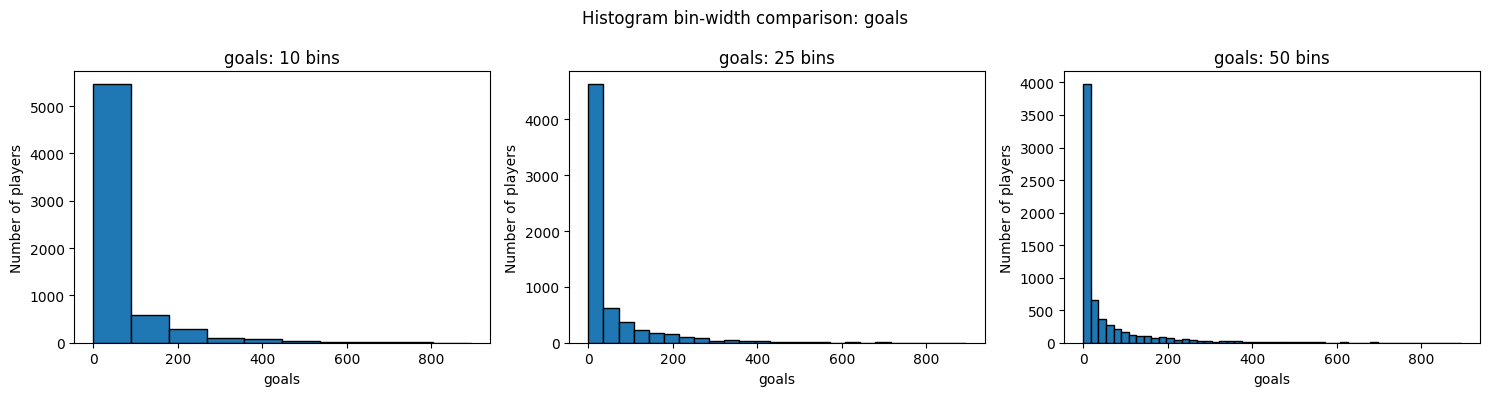

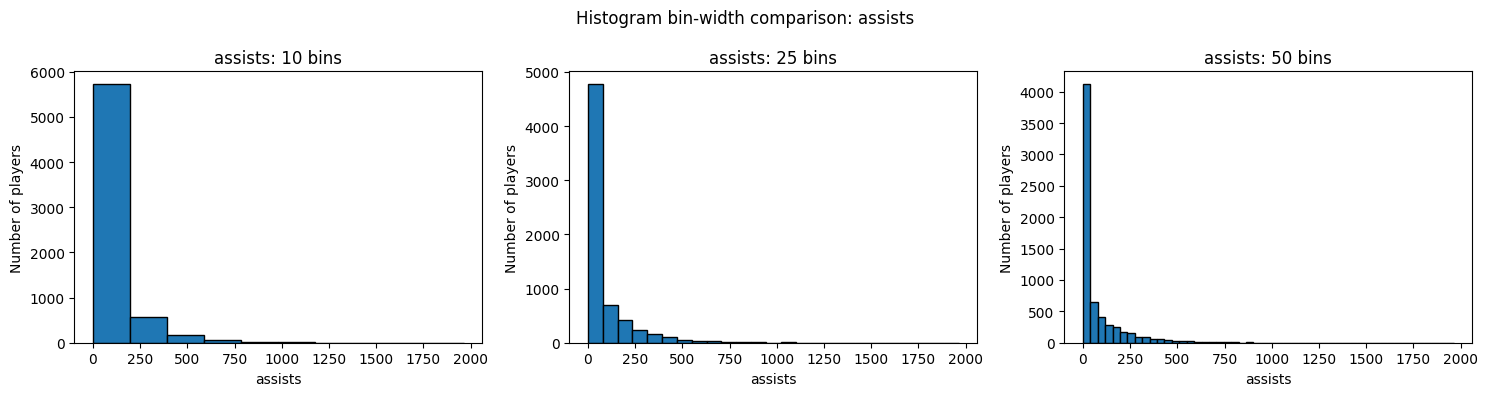

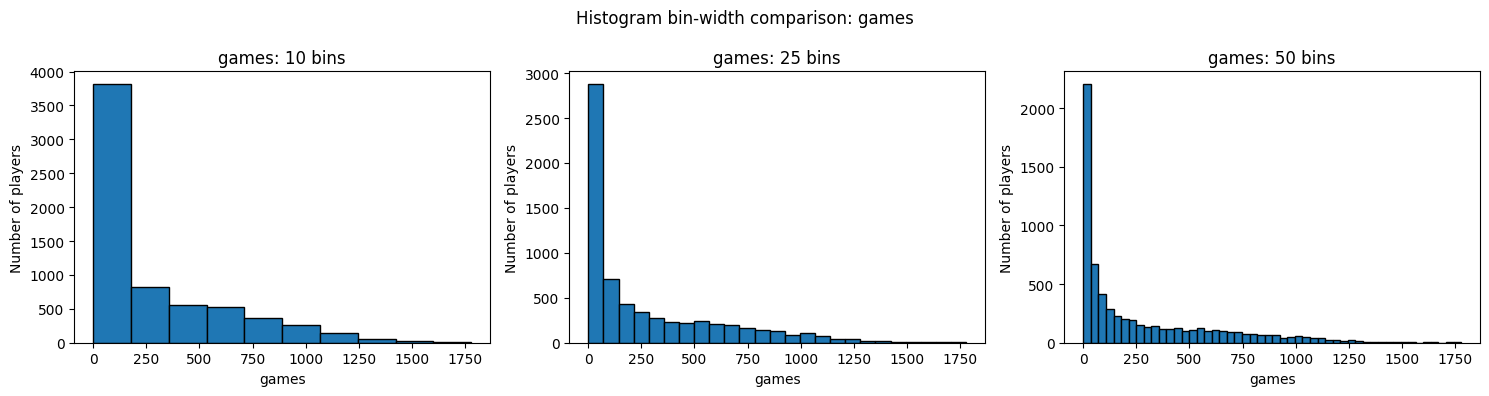

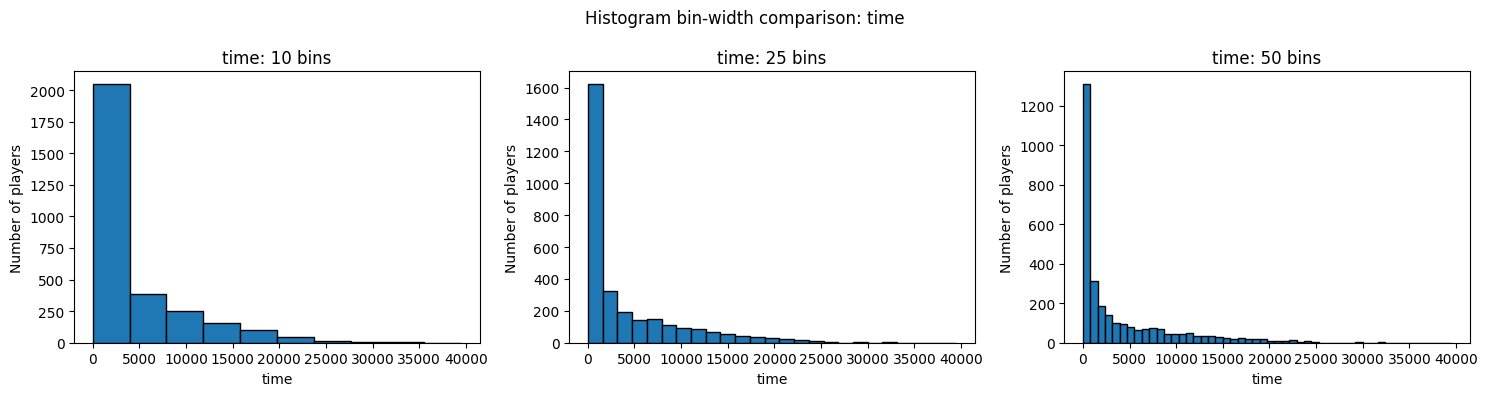

In [99]:
for col in numeric_cols:
    values = df[col].dropna()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, bins in zip(axes, [10, 25, 50]):
        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_title(f"{col}: {bins} bins")
        ax.set_xlabel(col)
        ax.set_ylabel("Number of players")

    fig.suptitle(f"Histogram bin-width comparison: {col}")
    plt.tight_layout()
    plt.show()

Interpretation:
- Right skew: many players with lower totals and a smaller number with very high totals. This is plausible for career goals, assists, and time-on-ice totals.

#### Checking the association between features

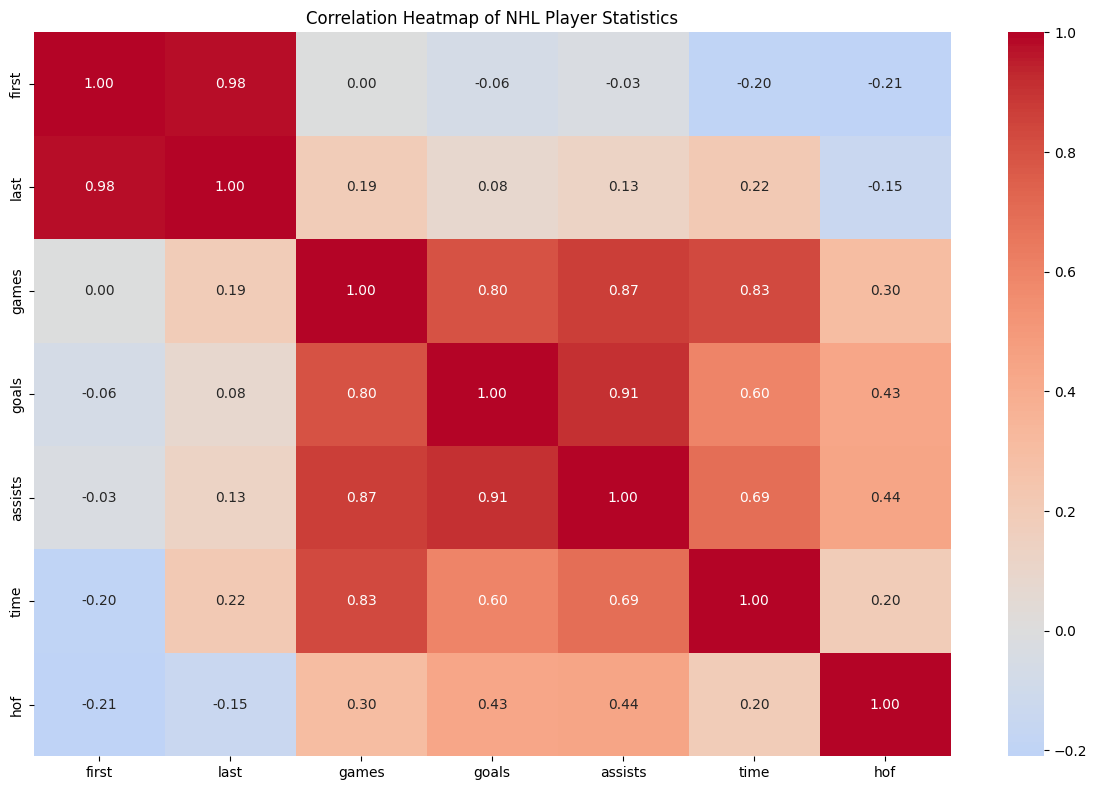

In [100]:
# visiualization - heat map to show association
# Select numerical columns
numeric_df = eligible_skaters.select_dtypes(include="number")
numeric_df
# Calculate correlations
corr = numeric_df.corr()
# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of NHL Player Statistics")
plt.tight_layout()

Interpretation:
From the heatmap, it is observed that hof has positive linear association with games, goals,assists and time, with highest association with goals and assists.

### Cleaning data
time = Nan
goals = 0
games = 0
dropping such rows

1) The players with zero games played is not eligible for hof, though they may have won different competition but due to strict NHL.

In [101]:
eligible_skaters.value_counts(eligible_skaters["games"] == 0)
eligible_skaters[eligible_skaters["games"] == 0]

,name,first,last,position,games,goals,assists,time,active,hof
4210,Dave Lucas,1963,1963,D,0,0,0,NaN,False,0


In [ ]:
# Stratified train/test split.

#### Feature Engineering - 
1) CareerLength = EndYear - StartYear + 1
2) GoalsPerGame = {TotalGoals}/{GamesPlayed}
3) AssistsPerGame = {TotalAssists}/{GamesPlayed}
4) career era
For example, a player's 300 goals in one era might represent a different level of achievement from 300 goals in another era.

You could create:
- 1910s–1940s
- 1950s
- 1960s
- 1970s
- 1980s
- 1990s
- 2000s
- 2010s
- 2020s
Alternatively, use decade as a categorical feature.
5) time on ice


In [ ]:

# CareerLength = EndYear - StartYear + 1
eligible_skaters["career_length"] = (
    eligible_skaters["last"] -
    eligible_skaters["first"] + 1
)

eligible_skaters.head()

,name,first,last,position,games,goals,assists,time,active,hof,career_length
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,0,4
2,Reg Abbott,1953,1953,C,3,0,0,NaN,False,0,1
3,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,0,4
4,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,0,13
5,Clarence Abel,1927,1934,D,333,20,18,NaN,False,0,8


In [47]:
# GoalsPerGame = {TotalGoals}/{GamesPlayed}
eligible_skaters["GoalsPerGame"] = (
    eligible_skaters["goals"] /
    eligible_skaters["games"] 
)
eligible_skaters.head()

,name,first,last,position,games,goals,assists,time,active,hof,career_length,GoalsPerGame
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,0,4,0.072848
2,Reg Abbott,1953,1953,C,3,0,0,NaN,False,0,1,0.000000
3,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,0,4,0.000000
4,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,0,13,0.143437
5,Clarence Abel,1927,1934,D,333,20,18,NaN,False,0,8,0.060060


In [48]:
# AssistsPerGame = {TotalAssists}/{GamesPlayed}
eligible_skaters["AssistsPerGame"] = (
    eligible_skaters["assists"] /
    eligible_skaters["games"] 
)
eligible_skaters.head()

,name,first,last,position,games,goals,assists,time,active,hof,career_length,GoalsPerGame,AssistsPerGame
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,0,4,0.072848,0.112583
2,Reg Abbott,1953,1953,C,3,0,0,NaN,False,0,1,0.000000,0.000000
3,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,0,4,0.000000,0.000000
4,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,0,13,0.143437,0.197564
5,Clarence Abel,1927,1934,D,333,20,18,NaN,False,0,8,0.060060,0.054054


# MERGED DATASET

#### MERGING SKATERS AND GOLIES 

In [ ]:
# giving positions for goalies
eligible_goalies["position"] = "Goalie"

In [175]:
# miniutes of goalies and time of skaters indicates same unit
eligible_goalies = eligible_goalies.rename(columns={"minutes":"time"})

In [180]:
eligible_goalies.isna().sum()

name          0
first         0
last          0
games         0
started     525
wins          2
losses        2
conceded      0
saves        88
time          0
goals         0
assists       0
active        0
hof           0
position      0
dtype: int64

In [181]:
eligible_skaters.isna().sum()

name           0
first          0
last           0
position       0
games          0
goals          0
assists        0
time        3566
active         0
hof            0
dtype: int64

In [177]:
# Combine both datasets
players = pd.concat(
    [eligible_skaters, eligible_goalies],
    ignore_index=True,
    sort=False
)

In [178]:
players

,name,first,last,position,games,goals,assists,time,active,hof,started,wins,losses,conceded,saves
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,False,NaN,NaN,NaN,NaN,NaN
1,Reg Abbott,1953,1953,C,3,0,0,NaN,False,False,NaN,NaN,NaN,NaN,NaN
2,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,False,NaN,NaN,NaN,NaN,NaN
3,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,False,NaN,NaN,NaN,NaN,NaN
4,Clarence Abel,1927,1934,D,333,20,18,NaN,False,False,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7299,Matt Zaba,2010,2010,Goalie,1,0,0,34.0,False,False,0.0,0.0,0.0,2.0,14.0
7300,Artyom Zagidulin,2021,2021,Goalie,1,0,0,28.0,False,False,0.0,0.0,0.0,2.0,9.0
7301,Mike Zanier,1985,1985,Goalie,3,0,0,185.0,False,False,NaN,1.0,1.0,12.0,88.0
7302,Jeff Zatkoff,2014,2017,Goalie,48,0,1,2490.0,False,False,37.0,18.0,21.0,113.0,1117.0


In [179]:
# exporting merged data to reuse
players.to_csv("/Users/arpitagonnade/Arpita_study_materials/Data Mining/Python_practise/DATS6103-final-project/Dataset/Merged_data.csv", index=False)
# /Users/arpitagonnade/Arpita_study_materials/Data Mining/Python_practise/DATS6103-final-project/Dataset/SKATERS.csv